# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Agente DQN completo - versión de Agustín (enfoque C: exploración, semillas y evaluación)

Este cuaderno es una copia de `LunarLander_DQN_Tarea.ipynb` con el **TODO 1 resuelto**
(agente DQN completo) y una sección 11 con el **prototipo del enfoque C**:

| Qué pide el enfoque C | Dónde está |
|---|---|
| Agente completo, curva de aprendizaje y evaluación | Secciones 6, 7 y 8 |
| Comparación pequeña de **dos esquemas de exploración** | Sección 11.3 a 11.5 (`lineal` vs `exponencial`) |
| Interruptor de prototipo para **apagar la exploración** | Parámetro `exploracion='ninguna'` del agente, variante `sin_exploracion` |
| **Semillas** y reproducibilidad | Sección 11.1 (dos corridas con la misma semilla dan exactamente lo mismo) |
| **Evaluación** honesta | Semillas separadas de entrenamiento / validación / test (sección 11.2) |
| Hiperparámetros exactos, semillas y tiempos | Sección 6.1 y 11.6 (también en `resultados/configuracion.json`) |

La explicación línea por línea y la teoría están en `EXPLICACION_AgenteDQN.md`, en esta
misma carpeta. Los TODO 2 (cortes de la política) y TODO 3 (ablación completa) quedan para
el trabajo en grupo.

## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [1]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

# >=1.0 porque LunarLander-v3 existe desde ahí; las anteriores registran solo v2.
# scipy (tests estadísticos) y joblib (correr semillas en paralelo) los agrega el enfoque C.
%pip install -q "gymnasium[box2d]>=1.0" matplotlib scipy joblib
# Aparte y con --index-url para traer la versión de CPU de torch (≈200 MB) y no la
# de CUDA, que es la que pip elegiría por omisión en Linux.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: C:\Users\Usuario\rlvenv\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
kernel: C:\Users\Usuario\rlvenv\Scripts\python.exe



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: C:\Users\Usuario\rlvenv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
# Importar las bibliotecas
import contextlib
import io
import json
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple
from pathlib import Path

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from joblib import Parallel, delayed
from scipy import stats

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

# La red es chica (8 -> 128 -> 128 -> 4): con un solo hilo PyTorch es igual o más
# rápido que con varios, y además los resultados no dependen de cuántos núcleos haya.
torch.set_num_threads(1)

# Carpeta donde se guardan pesos y resultados, para no reentrenar en cada sesión.
CARPETA_RESULTADOS = Path('resultados')
CARPETA_RESULTADOS.mkdir(exist_ok=True)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.14.1+cpu | dispositivo: cpu


## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [3]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 1
Estado siguiente: [ 0.004  1.425  0.22   0.295 -0.003 -0.004  0.     0.   ]
Recompensa: 2.080
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [4]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [5]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [6]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto


def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()


Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -177.63
Recompensa mediana:  -140.74
Desviación estándar: 112.47
Total de éxitos: 0 / 100


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [7]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

El agente sigue el algoritmo de Mnih et al. (2015), *Human-level control through deep
reinforcement learning*, adaptado a un estado de 8 números (no hay imágenes, así que la
red es un perceptrón multicapa y no una convolucional):

1. **Red Q** $Q(s,\cdot;\theta)$: recibe el estado y devuelve un valor por acción.
2. **Memoria de repetición** (*replay buffer*): guarda transiciones $(s,a,r,s',\text{terminado})$
   y se entrena con minilotes sorteados al azar, lo que rompe la correlación entre pasos seguidos.
3. **Red objetivo** $Q(s,\cdot;\theta^-)$: copia lenta de la red Q que se usa para calcular el
   objetivo $y = r + \gamma\,(1-\text{terminado})\max_{a'} Q(s',a';\theta^-)$.
4. **Exploración ε-greedy**: con probabilidad ε se elige una acción al azar y si no la de mayor Q.
   El enfoque C agrega tres modos: `lineal` (ε baja por **pasos**), `exponencial` (ε baja por
   **episodios**) y `ninguna` (ε = 0 siempre, el interruptor para apagar la exploración).

Todo lo que necesita el agente (la red, la memoria y la actualización) vive dentro de la clase,
como pide la letra.

In [8]:
# Implementación del agente DQN
class AgenteDQN(Agente):
    """Agente de Red Q Profunda.

    `semilla` fija los generadores (random, NumPy, PyTorch y `accion_space.seed`).
    `elegir_accion(estado, explorar=False)` devuelve la acción greedy, sin explorar.
    `fin_episodio()` se invoca al terminar cada episodio de entrenamiento.

    Esquemas de exploración (`exploracion`):
      * 'lineal':      ε baja en línea recta de `eps_inicio` a `eps_fin` en `pasos_decaimiento` pasos.
      * 'exponencial': ε se multiplica por `factor_decaimiento` al final de cada episodio.
      * 'ninguna':     ε = 0 siempre (interruptor de prototipo: sin exploración).
    """

    class RedQ(nn.Module):
        """Perceptrón multicapa: estado (8) -> capas ocultas con ReLU -> un valor Q por acción (4)."""

        def __init__(self, dim_estado, n_acciones, capas_ocultas):
            super().__init__()
            capas = []
            entrada = dim_estado
            for salida in capas_ocultas:
                capas.append(nn.Linear(entrada, salida))
                capas.append(nn.ReLU())
                entrada = salida
            capas.append(nn.Linear(entrada, n_acciones))   # salida lineal: los Q pueden ser negativos
            self.red = nn.Sequential(*capas)

        def forward(self, x):
            return self.red(x)

    def __init__(self, estado_space, accion_space, semilla=None,
                 capas_ocultas=(128, 128), lr=5e-4, gamma=0.99,
                 tam_buffer=100_000, tam_lote=64, min_buffer=1_000,
                 entrenar_cada=4, tau=1e-3,
                 exploracion='lineal', eps_inicio=1.0, eps_fin=0.01,
                 pasos_decaimiento=50_000, factor_decaimiento=0.995):
        # --- Semillas: todos los generadores de números aleatorios que intervienen ---
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)       # inicialización de los pesos de la red
            accion_space.seed(semilla)       # RNG propio de Gymnasium (acciones al azar)
        self.rng = np.random.default_rng(semilla)   # RNG propio: moneda de ε y sorteo del minilote

        # --- Datos del problema ---
        self.accion_space = accion_space
        self.dim_estado = estado_space.shape[0]     # 8
        self.n_acciones = accion_space.n            # 4

        # --- Hiperparámetros de aprendizaje ---
        self.gamma = gamma                          # factor de descuento
        self.tam_lote = tam_lote                    # transiciones por minilote
        self.min_buffer = max(min_buffer, tam_lote) # no entrenar hasta tener esta cantidad
        self.entrenar_cada = entrenar_cada          # un paso de gradiente cada tantos pasos
        self.tau = tau                              # velocidad de la red objetivo

        # --- Redes: Q (la que se entrena) y objetivo (copia lenta) ---
        self.red_q = self.RedQ(self.dim_estado, self.n_acciones, capas_ocultas)
        self.red_objetivo = self.RedQ(self.dim_estado, self.n_acciones, capas_ocultas)
        self.red_objetivo.load_state_dict(self.red_q.state_dict())   # arrancan iguales
        self.red_objetivo.eval()
        self.optimizador = optim.Adam(self.red_q.parameters(), lr=lr)

        # --- Memoria de repetición: arreglos circulares de NumPy ---
        self.tam_buffer = tam_buffer
        self.buf_estados = np.zeros((tam_buffer, self.dim_estado), dtype=np.float32)
        self.buf_acciones = np.zeros(tam_buffer, dtype=np.int64)
        self.buf_recompensas = np.zeros(tam_buffer, dtype=np.float32)
        self.buf_siguientes = np.zeros((tam_buffer, self.dim_estado), dtype=np.float32)
        self.buf_terminados = np.zeros(tam_buffer, dtype=np.float32)
        self.pos_buffer = 0      # dónde se escribe la próxima transición
        self.n_buffer = 0        # cuántas transiciones válidas hay

        # --- Exploración (enfoque C) ---
        if exploracion not in ('lineal', 'exponencial', 'ninguna'):
            raise ValueError(f"exploracion desconocida: {exploracion!r}")
        self.exploracion = exploracion
        self.eps_inicio = eps_inicio
        self.eps_fin = eps_fin
        self.pasos_decaimiento = pasos_decaimiento
        self.factor_decaimiento = factor_decaimiento
        self.epsilon = 0.0 if exploracion == 'ninguna' else eps_inicio

        # --- Contadores ---
        self.pasos = 0             # pasos de entorno vistos en entrenamiento
        self.episodios = 0         # episodios de entrenamiento terminados
        self.actualizaciones = 0   # pasos de gradiente hechos

    def elegir_accion(self, estado, explorar=True):
        """Elige acción; sin exploración si `explorar=False`."""
        if explorar and self.rng.random() < self.epsilon:
            return int(self.accion_space.sample())          # explorar: acción al azar
        with torch.no_grad():                                # explotar: argmax_a Q(s, a)
            q = self.red_q(torch.as_tensor(estado, dtype=torch.float32).unsqueeze(0))
        return int(q.argmax(dim=1).item())

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Almacena la experiencia y entrena la red."""
        # 1) Guardar la transición en la memoria circular (pisa la más vieja si está llena)
        i = self.pos_buffer
        self.buf_estados[i] = estado
        self.buf_acciones[i] = accion
        self.buf_recompensas[i] = recompensa
        self.buf_siguientes[i] = siguiente_estado
        self.buf_terminados[i] = float(terminado)
        self.pos_buffer = (i + 1) % self.tam_buffer
        self.n_buffer = min(self.n_buffer + 1, self.tam_buffer)
        self.pasos += 1

        # 2) Esquema lineal: ε depende de cuántos pasos se dieron
        if self.exploracion == 'lineal':
            fraccion = min(1.0, self.pasos / self.pasos_decaimiento)
            self.epsilon = self.eps_inicio + fraccion * (self.eps_fin - self.eps_inicio)

        # 3) Cada `entrenar_cada` pasos, y si ya hay suficientes datos, un paso de gradiente
        if self.pasos % self.entrenar_cada == 0 and self.n_buffer >= self.min_buffer:
            self._paso_de_gradiente()

    def _paso_de_gradiente(self):
        """Un paso de descenso por gradiente sobre un minilote sorteado de la memoria."""
        idx = self.rng.integers(0, self.n_buffer, size=self.tam_lote)
        estados = torch.from_numpy(self.buf_estados[idx])
        acciones = torch.from_numpy(self.buf_acciones[idx])
        recompensas = torch.from_numpy(self.buf_recompensas[idx])
        siguientes = torch.from_numpy(self.buf_siguientes[idx])
        terminados = torch.from_numpy(self.buf_terminados[idx])

        # Q(s, a; θ) de la acción que efectivamente se tomó
        q_actual = self.red_q(estados).gather(1, acciones.unsqueeze(1)).squeeze(1)

        # Objetivo de Bellman con la red objetivo; sin gradiente porque es "la etiqueta"
        with torch.no_grad():
            q_siguiente = self.red_objetivo(siguientes).max(dim=1).values
            objetivo = recompensas + self.gamma * (1.0 - terminados) * q_siguiente

        # Pérdida de Huber (equivale al recorte del error del artículo) y paso de Adam
        perdida = F.smooth_l1_loss(q_actual, objetivo)
        self.optimizador.zero_grad()
        perdida.backward()
        nn.utils.clip_grad_norm_(self.red_q.parameters(), 10.0)
        self.optimizador.step()
        self.actualizaciones += 1

        # Actualización suave de la red objetivo: θ⁻ ← τ·θ + (1 − τ)·θ⁻
        with torch.no_grad():
            for p_obj, p in zip(self.red_objetivo.parameters(), self.red_q.parameters()):
                p_obj.mul_(1.0 - self.tau).add_(self.tau * p)

    def fin_episodio(self):
        """El bucle de entrenamiento lo invoca al terminar cada episodio."""
        self.episodios += 1
        # Esquema exponencial: ε depende de cuántos episodios se jugaron
        if self.exploracion == 'exponencial':
            self.epsilon = max(self.eps_fin, self.epsilon * self.factor_decaimiento)


# Prueba rápida de la interfaz
env = gym.make('LunarLander-v3')
_prueba = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA)
_estado, _ = env.reset(seed=SEMILLA)
print("Acción greedy:", _prueba.elegir_accion(_estado, explorar=False),
      "| ε inicial:", _prueba.epsilon,
      "| parámetros de la red:", sum(p.numel() for p in _prueba.red_q.parameters()))
env.close()

Acción greedy: 3 | ε inicial: 1.0 | parámetros de la red: 18180


### 6.1 Hiperparámetros y semillas usados

Todos los entrenamientos de este cuaderno usan exactamente estos valores. Se tomaron de
configuraciones conocidas para LunarLander con DQN (red 128×128, Adam 5·10⁻⁴, memoria de 100 000,
minilote 64, entrenar cada 4 pasos, τ = 10⁻³) **sin búsqueda de hiperparámetros**: lo único que se
varía a propósito es la exploración (enfoque C, sección 11).

| Semillas | Valor |
|---|---|
| Agente del entrenamiento principal | `SEMILLA = 42` (resets del entorno: 42, 43, …) |
| Experimento de exploración (agente) | 0, 1, 2, 3, 4 |
| Experimento de exploración (resets) | `100 000 + 1000·semilla + episodio` |
| Validación durante el entrenamiento | 50 000 … 50 009 |
| Test (evaluación final) | 10 000 … 10 199 (sección 8) y 10 000 … 10 099 (sección 11) |
| GIF | sorteadas entre 20 000 y 30 000 con `default_rng(42)` |

In [9]:
HIPERPARAMETROS = dict(
    capas_ocultas=(128, 128),   # dos capas ocultas de 128 neuronas
    lr=5e-4,                    # tasa de aprendizaje de Adam
    gamma=0.99,                 # factor de descuento
    tam_buffer=100_000,         # capacidad de la memoria de repetición
    tam_lote=64,                # tamaño del minilote
    min_buffer=1_000,           # transiciones mínimas antes de entrenar
    entrenar_cada=4,            # un paso de gradiente cada 4 pasos de entorno
    tau=1e-3,                   # actualización suave de la red objetivo
    eps_inicio=1.0,             # ε al empezar
    eps_fin=0.01,               # ε mínimo
    pasos_decaimiento=50_000,   # esquema lineal: pasos para ir de 1.0 a 0.01
    factor_decaimiento=0.995,   # esquema exponencial: ε ← ε · 0.995 por episodio
)

# Esquema elegido para el entrenamiento principal: un prototipo de una semilla lo favoreció y
# las curvas de VALIDACIÓN de la sección 11 lo confirman (el test no se usó para elegir).
EXPLORACION_PRINCIPAL = 'exponencial'

print(json.dumps({**HIPERPARAMETROS, 'exploracion': EXPLORACION_PRINCIPAL}, indent=2))

{
  "capas_ocultas": [
    128,
    128
  ],
  "lr": 0.0005,
  "gamma": 0.99,
  "tam_buffer": 100000,
  "tam_lote": 64,
  "min_buffer": 1000,
  "entrenar_cada": 4,
  "tau": 0.001,
  "eps_inicio": 1.0,
  "eps_fin": 0.01,
  "pasos_decaimiento": 50000,
  "factor_decaimiento": 0.995,
  "exploracion": "exponencial"
}


## 7. Entrenamiento del agente DQN

Se entrena 1200 episodios de hasta 1000 pasos con la semilla 42, sin parada temprana.

Los pesos y las curvas se guardan en `resultados/`. Si ya existen se cargan en lugar de
reentrenar (poner `REENTRENAR = True` para forzar el entrenamiento).

In [10]:
# Entrenar el agente DQN (o cargarlo de disco si ya se entrenó)
REENTRENAR = False
RUTA_PESOS = CARPETA_RESULTADOS / 'dqn_principal.pt'
RUTA_CURVAS = CARPETA_RESULTADOS / 'dqn_principal_curvas.json'

env = gym.make('LunarLander-v3')
agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA,
                       exploracion=EXPLORACION_PRINCIPAL, **HIPERPARAMETROS)

if RUTA_PESOS.exists() and RUTA_CURVAS.exists() and not REENTRENAR:
    agente_dqn.red_q.load_state_dict(torch.load(RUTA_PESOS))
    guardado = json.loads(RUTA_CURVAS.read_text())
    recompensas_episodios = guardado['recompensas']
    longitudes_episodios = guardado['longitudes']
    agente_dqn.epsilon = guardado['epsilon_final']
    tiempo_principal = guardado['tiempo_s']
    print(f"Cargado de {RUTA_PESOS} (entrenamiento original: {tiempo_principal / 60:.1f} min)")
else:
    print("\nEntrenando el agente DQN en LunarLander-v3...")
    t0 = time.time()
    recompensas_episodios, longitudes_episodios = entrenar_agente(
        agente_dqn, env,
        num_episodios=1200,
        max_pasos=1000,
        umbral_resolucion=None,   # sin parada temprana: se quiere la curva completa
        semilla=SEMILLA,
        verbose=True,
    )
    tiempo_principal = time.time() - t0
    torch.save(agente_dqn.red_q.state_dict(), RUTA_PESOS)
    RUTA_CURVAS.write_text(json.dumps({
        'recompensas': [float(r) for r in recompensas_episodios],
        'longitudes': [int(l) for l in longitudes_episodios],
        'epsilon_final': agente_dqn.epsilon,
        'pasos_totales': agente_dqn.pasos,
        'actualizaciones': agente_dqn.actualizaciones,
        'tiempo_s': tiempo_principal,
    }))

print(f"Tiempo de entrenamiento: {tiempo_principal / 60:.1f} min "
      f"({sum(longitudes_episodios):,} pasos de entorno)")
env.close()


Entrenando el agente DQN en LunarLander-v3...


Episodio    60 | Recompensa media (100 ep):  -161.71 | Longitud media:  103.5 | epsilon: 0.740 |     6s


Episodio   120 | Recompensa media (100 ep):  -128.35 | Longitud media:  131.5 | epsilon: 0.548 |    14s


Episodio   180 | Recompensa media (100 ep):   -76.38 | Longitud media:  247.3 | epsilon: 0.406 |    31s


Episodio   240 | Recompensa media (100 ep):   -30.18 | Longitud media:  529.3 | epsilon: 0.300 |    71s


...

Episodio  1080 | Recompensa media (100 ep):   243.21 | Longitud media:  390.4 | epsilon: 0.010 |   564s


Episodio  1140 | Recompensa media (100 ep):   244.10 | Longitud media:  366.6 | epsilon: 0.010 |   586s


Episodio  1200 | Recompensa media (100 ep):   246.73 | Longitud media:  380.4 | epsilon: 0.010 |   607s


Tiempo total de entrenamiento: 607s


Tiempo de entrenamiento: 10.1 min (558,856 pasos de entorno)


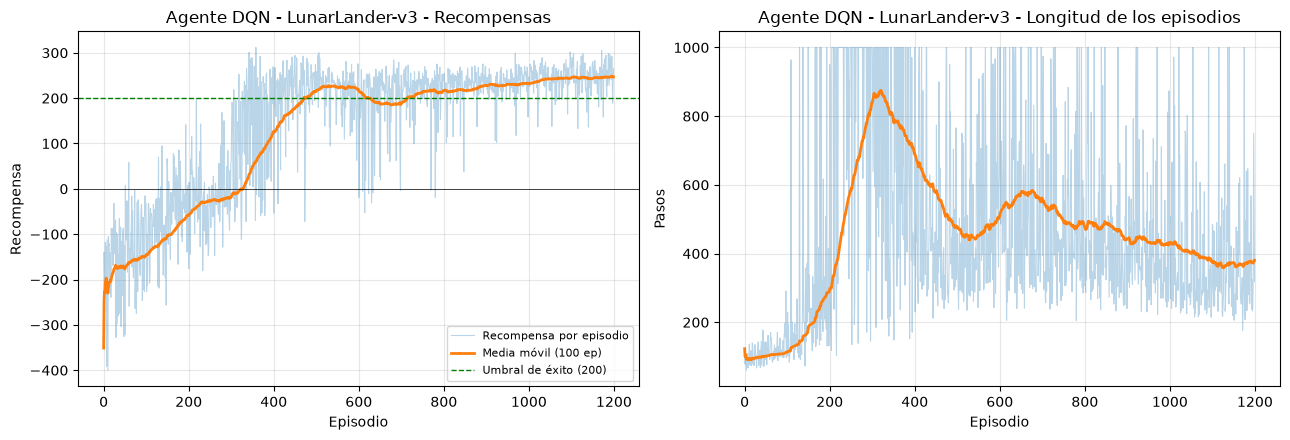

Resultados de los últimos 100 episodios de entrenamiento:
Recompensa promedio: 246.73
Tasa de éxito (R ≥ 200): 92.0%
Epsilon final: 0.010


In [11]:
# Graficar progreso del entrenamiento
graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                "Agente DQN - LunarLander-v3")

# Resultados del final del entrenamiento (todavía con exploración residual)
ultimos = np.array(recompensas_episodios[-100:])
print("Resultados de los últimos 100 episodios de entrenamiento:")
print(f"Recompensa promedio: {ultimos.mean():.2f}")
print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")

## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [12]:
# Evaluar el agente DQN entrenado
env = gym.make('LunarLander-v3')

print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

print("\nImplementación de referencia para comparar:")
resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                          num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

env.close()

Evaluando agente DQN entrenado (200 episodios, sin exploración)...



Agente DQN entrenado - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 65.0%
Recompensa promedio: 217.99
Recompensa mediana:  237.55
Desviación estándar: 58.31
Total de éxitos: 130 / 200

Implementación de referencia para comparar:



Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200


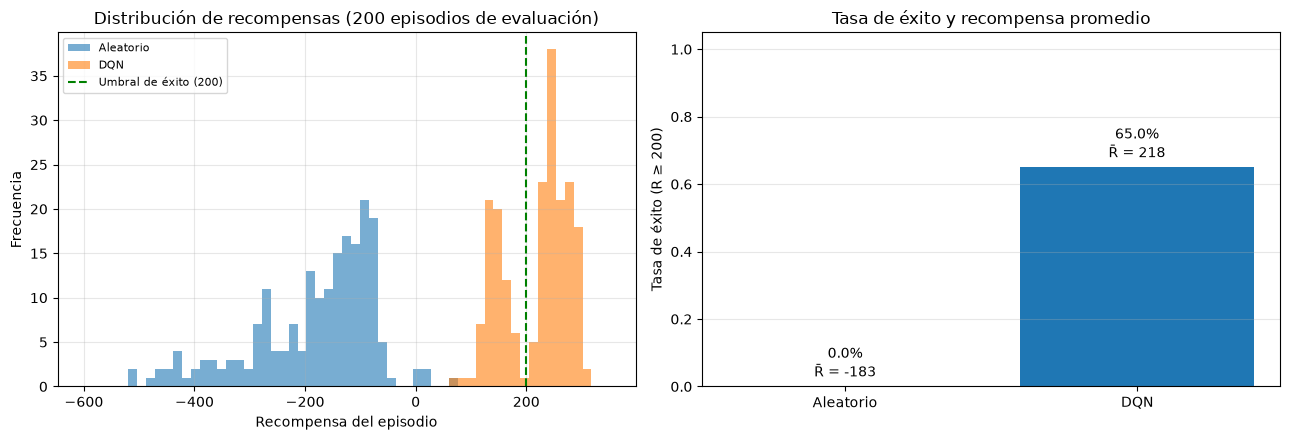

Tasa de éxito DQN:       65.0%
Tasa de éxito Aleatorio: 0.0%
Mejora en recompensa promedio: 401.2 puntos

Desglose de los 200 episodios del DQN:
  R ≥  200:  65.0%
  R ≥  150:  81.0%
  R ≥  100:  99.0%
  R ≥    0: 100.0%
  Episodios que se estrellan (R < -50): 0.0%


In [13]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print("\nDesglose de los 200 episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")

## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

  semilla 20892: 1000 pasos, recompensa   151.0


  semilla 27739:  360 pasos, recompensa   244.6


  semilla 26545:  271 pasos, recompensa   236.3


  semilla 24388:  293 pasos, recompensa   261.7


  semilla 24330:  868 pasos, recompensa   280.4


...

  semilla 20859:  270 pasos, recompensa   230.0


  semilla 26973:  221 pasos, recompensa   290.5


  semilla 22014: 1000 pasos, recompensa   118.2


  semilla 20941:  247 pasos, recompensa   228.7



8/10 episodios exitosos, recompensa media 231.4 → aterrizaje_dqn.gif


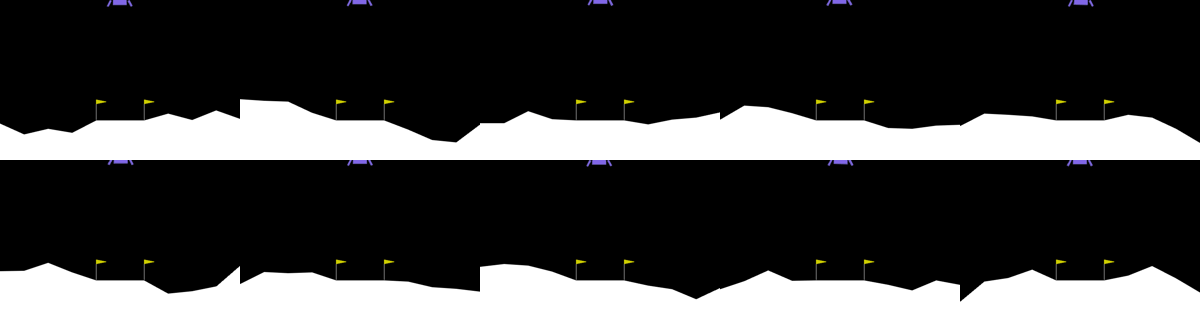

In [14]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


# Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
display(MostrarImagen(filename=ruta))

## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


In [15]:
# TODO 2: cortes de la política. Queda para el trabajo en grupo (fuera del enfoque C).
print("TODO 2 pendiente")

TODO 2 pendiente


## 11. Prototipo del enfoque C: exploración, semillas y evaluación

Esta sección **no** es todavía el estudio de ablación completo (TODO 3), pero deja armadas las
piezas que el grupo necesita para hacerlo:

* **11.1** Comprobación de que las semillas hacen el entrenamiento reproducible.
* **11.2** Una función que entrena y, cada 50 episodios, mide la política **greedy** sobre semillas
  de validación (separadas de las de test).
* **11.3** Comparación de dos esquemas de exploración (`lineal` vs `exponencial`) y el interruptor
  `sin_exploracion`, con 5 semillas cada uno, en paralelo y guardando los resultados en disco.
* **11.4–11.5** Curvas, evaluación sobre las mismas semillas de test y test estadístico.
* **11.6** Tiempos medidos y presupuesto para la ablación.

### 11.1 Semillas y reproducibilidad

Se entrena 20 episodios dos veces con la misma semilla y una vez con otra. Si todos los
generadores están fijados (Python, NumPy, PyTorch, el RNG del espacio de acciones, el RNG propio
del agente y los `reset` del entorno), las dos primeras corridas deben coincidir **exactamente**,
recompensa por recompensa y peso por peso.

In [16]:
def huella_entrenamiento(semilla, n_episodios=20, exploracion='lineal'):
    """Entrena un agente nuevo unos pocos episodios y devuelve (recompensas, pesos aplanados)."""
    env = gym.make('LunarLander-v3')
    agente = AgenteDQN(env.observation_space, env.action_space, semilla=semilla,
                       **{**HIPERPARAMETROS, 'exploracion': exploracion})
    with contextlib.redirect_stdout(io.StringIO()):     # silencia el "Tiempo total"
        recompensas, _ = entrenar_agente(agente, env, num_episodios=n_episodios,
                                         verbose=False, semilla=semilla)
    env.close()
    pesos = torch.cat([p.detach().flatten() for p in agente.red_q.parameters()])
    return np.array(recompensas), pesos


r_a, w_a = huella_entrenamiento(7)
r_b, w_b = huella_entrenamiento(7)
r_c, w_c = huella_entrenamiento(8)

print("Semilla 7, corrida A:", np.round(r_a[-5:], 2))
print("Semilla 7, corrida B:", np.round(r_b[-5:], 2))
print("Semilla 8          :", np.round(r_c[-5:], 2))
print(f"\nA y B idénticas (recompensas): {np.array_equal(r_a, r_b)}")
print(f"A y B idénticas (pesos):       {torch.equal(w_a, w_b)}")
print(f"A y semilla 8 distintas:       {not np.array_equal(r_a, r_c)}")
assert np.array_equal(r_a, r_b) and torch.equal(w_a, w_b), "El entrenamiento no es reproducible"

Semilla 7, corrida A: [-146.29 -248.79   36.38 -267.07 -234.78]
Semilla 7, corrida B: [-146.29 -248.79   36.38 -267.07 -234.78]
Semilla 8          : [-133.99 -241.95  -77.47 -124.33 -145.5 ]

A y B idénticas (recompensas): True
A y B idénticas (pesos):       True
A y semilla 8 distintas:       True


### 11.2 Entrenar con validación periódica

La curva de entrenamiento mezcla dos cosas: lo que sabe la red y el ruido que mete ε. Para ver
**solo la política aprendida** se entrena por bloques de 50 episodios (llamando a
`entrenar_agente` sin modificarla) y después de cada bloque se evalúa sin exploración en 10
episodios de **validación** (semillas 50 000…50 009).

Tres juegos de semillas que no se pisan:

* **entrenamiento**: `100 000 + 1000·semilla + episodio` (cada semilla del agente ve escenarios distintos),
* **validación**: 50 000…50 009 (para mirar la curva y elegir configuraciones),
* **test**: 10 000…10 099 (solo para el número final; no se usa para elegir nada).

In [17]:
SEMILLA_VALIDACION = 50_000
SEMILLA_TEST = 10_000


def semilla_entorno(semilla_agente):
    """Semilla base de los resets de entrenamiento: no se pisa con validación ni test."""
    return 100_000 + 1_000 * semilla_agente


def entrenar_con_validacion(agente, env, num_episodios, semilla, cada=50, episodios_val=10):
    """Entrena por bloques de `cada` episodios y evalúa greedy al final de cada bloque."""
    recompensas, longitudes, validacion = [], [], []
    for inicio in range(0, num_episodios, cada):
        n = min(cada, num_episodios - inicio)
        with contextlib.redirect_stdout(io.StringIO()):
            r, l = entrenar_agente(agente, env, num_episodios=n, verbose=False,
                                   semilla=semilla + inicio)   # mismas semillas que de un tirón
        recompensas += r
        longitudes += l
        val = evaluar_agente(agente, env, num_episodios=episodios_val, semilla=SEMILLA_VALIDACION)
        validacion.append({'episodio': inicio + n,
                           'recompensa': val['recompensa_promedio'],
                           'tasa_exito': val['tasa_exito'],
                           'epsilon': agente.epsilon})
    return recompensas, longitudes, validacion

### 11.3 Experimento: dos esquemas de exploración y el interruptor

| Configuración | Qué hace ε | Idea |
|---|---|---|
| `lineal` | baja de 1.0 a 0.01 en 50 000 **pasos** y queda fija | explora mucho al principio, sin importar cuán largos sean los episodios |
| `exponencial` | ε ← ε · 0.995 al final de cada **episodio** (llega a 0.01 en ~920 episodios) | explora de forma más prolongada y pareja por episodio |
| `sin_exploracion` | ε = 0 siempre | interruptor del prototipo: ¿qué pasa si el agente nunca explora? |

Cada configuración se entrena con las semillas 0–4 durante `EPISODIOS_EXPERIMENTO` episodios
(menos que los 1200 del entrenamiento principal, para que entre en el presupuesto). Las 15 corridas
son independientes, así que se reparten entre los núcleos con `joblib`. Cada resultado se guarda
en `resultados/exploracion/<config>_s<semilla>.json` y solo se entrena lo que falta.

In [18]:
CONFIGURACIONES = {
    'lineal': dict(exploracion='lineal'),
    'exponencial': dict(exploracion='exponencial'),
    'sin_exploracion': dict(exploracion='ninguna'),
}
SEMILLAS_EXPERIMENTO = [0, 1, 2, 3, 4]
EPISODIOS_EXPERIMENTO = 600
EPISODIOS_TEST = 100
CARPETA_EXPLORACION = CARPETA_RESULTADOS / 'exploracion'
CARPETA_EXPLORACION.mkdir(exist_ok=True)


def correr_configuracion(nombre, semilla):
    """Entrena una configuración con una semilla, la evalúa en test y devuelve un dict serializable."""
    torch.set_num_threads(1)                       # cada proceso usa un solo núcleo
    env = gym.make('LunarLander-v3')
    agente = AgenteDQN(env.observation_space, env.action_space, semilla=semilla,
                       **{**HIPERPARAMETROS, **CONFIGURACIONES[nombre]})
    t0 = time.time()
    recompensas, longitudes, validacion = entrenar_con_validacion(
        agente, env, EPISODIOS_EXPERIMENTO, semilla=semilla_entorno(semilla))
    tiempo = time.time() - t0
    test = evaluar_agente(agente, env, num_episodios=EPISODIOS_TEST, semilla=SEMILLA_TEST)
    env.close()
    return {
        'config': nombre, 'semilla': semilla, 'tiempo_s': tiempo,
        'pasos_totales': agente.pasos,
        'recompensas': [float(r) for r in recompensas],
        'longitudes': [int(l) for l in longitudes],
        'validacion': validacion,
        'test_recompensas': test['recompensas_totales'].tolist(),
        'test_tasa_exito': test['tasa_exito'],
        'test_recompensa_promedio': test['recompensa_promedio'],
    }


def ruta_resultado(nombre, semilla):
    return CARPETA_EXPLORACION / f'{nombre}_s{semilla}.json'


pendientes = [(n, s) for n in CONFIGURACIONES for s in SEMILLAS_EXPERIMENTO
              if not ruta_resultado(n, s).exists()]
print(f"Corridas pendientes: {len(pendientes)} de {len(CONFIGURACIONES) * len(SEMILLAS_EXPERIMENTO)}")

if pendientes:
    t0 = time.time()
    nuevos = Parallel(n_jobs=min(len(pendientes), os.cpu_count()), verbose=5)(
        delayed(correr_configuracion)(n, s) for n, s in pendientes)
    for res in nuevos:
        ruta_resultado(res['config'], res['semilla']).write_text(json.dumps(res))
    print(f"Tiempo de pared del experimento: {(time.time() - t0) / 60:.1f} min "
          f"con {min(len(pendientes), os.cpu_count())} procesos")

resultados_exp = {n: [json.loads(ruta_resultado(n, s).read_text()) for s in SEMILLAS_EXPERIMENTO]
                  for n in CONFIGURACIONES}

Corridas pendientes: 15 de 15


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=8)]: Done   4 out of  15 | elapsed: 11.9min remaining: 32.6min


[Parallel(n_jobs=8)]: Done   8 out of  15 | elapsed: 13.8min remaining: 12.0min


[Parallel(n_jobs=8)]: Done  12 out of  15 | elapsed: 22.9min remaining:  5.7min


[Parallel(n_jobs=8)]: Done  15 out of  15 | elapsed: 24.9min finished


Tiempo de pared del experimento: 24.9 min con 8 procesos


### 11.4 Curvas de aprendizaje

Izquierda: recompensa de entrenamiento (media móvil de 100 episodios), promedio entre semillas con
banda de ± 1 desviación estándar. Centro: la política **greedy** medida en validación cada 50
episodios. Derecha: cómo evoluciona ε en cada esquema.

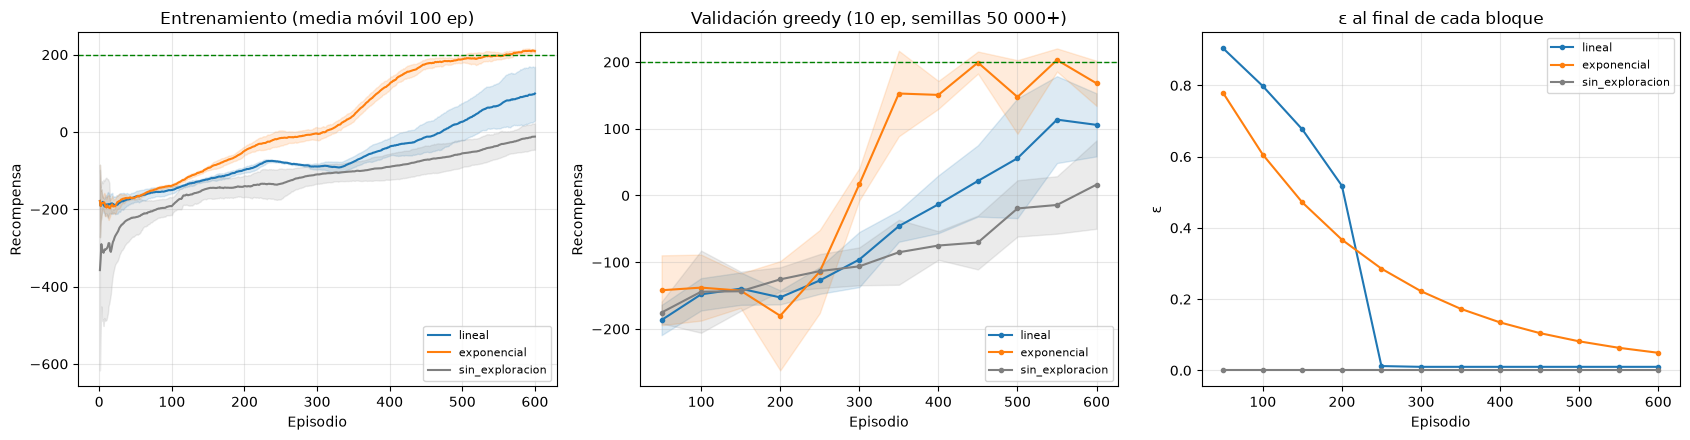

In [19]:
COLORES = {'lineal': 'tab:blue', 'exponencial': 'tab:orange', 'sin_exploracion': 'tab:gray'}

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5))
for nombre, corridas in resultados_exp.items():
    color = COLORES[nombre]
    curvas = np.array([media_movil(c['recompensas']) for c in corridas])
    x = np.arange(1, curvas.shape[1] + 1)
    ax1.plot(x, curvas.mean(0), color=color, label=nombre)
    ax1.fill_between(x, curvas.mean(0) - curvas.std(0), curvas.mean(0) + curvas.std(0),
                     color=color, alpha=0.15)

    ep_val = [v['episodio'] for v in corridas[0]['validacion']]
    val = np.array([[v['recompensa'] for v in c['validacion']] for c in corridas])
    ax2.plot(ep_val, val.mean(0), 'o-', color=color, label=nombre, markersize=3)
    ax2.fill_between(ep_val, val.mean(0) - val.std(0), val.mean(0) + val.std(0),
                     color=color, alpha=0.15)

    eps = np.array([[v['epsilon'] for v in c['validacion']] for c in corridas])
    ax3.plot(ep_val, eps.mean(0), 'o-', color=color, label=nombre, markersize=3)

for ax, titulo, ylabel in [(ax1, 'Entrenamiento (media móvil 100 ep)', 'Recompensa'),
                           (ax2, 'Validación greedy (10 ep, semillas 50 000+)', 'Recompensa'),
                           (ax3, 'ε al final de cada bloque', 'ε')]:
    if ax is not ax3:
        ax.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1)
    ax.set_title(titulo)
    ax.set_xlabel('Episodio')
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 11.5 Evaluación en test y test estadístico

Cada agente entrenado se evalúa sin exploración en las **mismas** 100 semillas de test
(10 000…10 099). La unidad de análisis es la **semilla de entrenamiento**: por cada una se resume
su recompensa media de test, así que cada configuración aporta 5 números independientes.

Para comparar cada variante contra `lineal` se usa el test **U de Mann-Whitney** (bilateral):
no supone normalidad, lo que importa porque con 5 semillas no se puede verificar y las
recompensas de LunarLander suelen ser bimodales (aterriza ≈ +250 o se estrella ≈ −100). Como
referencia se reporta también el test t de Welch. Con 5 contra 5 el p-valor más chico posible del
Mann-Whitney es 2/252 ≈ 0.008, así que solo diferencias muy consistentes salen significativas.

config                 s0       s1       s2       s3       s4    media    desv   éxito    min
lineal               99.5    177.1     99.9     80.7    178.1    127.1    46.8   40.6%   11.6
exponencial         213.3    169.2    137.1    175.5    190.6    177.1    28.1   48.0%    9.7
sin_exploracion      -6.5      0.4    -29.3    -27.3     93.2      6.1    50.3    4.6%   10.8

Tasa de éxito en test por semilla:
  lineal             41%    65%    23%    12%    62%
  exponencial        74%    48%    19%    39%    60%
  sin_exploracion     0%     0%     0%     0%    23%

Comparación contra 'lineal' (recompensa media de test por semilla, n = 5 por grupo):
  exponencial      diferencia de medias =    50.0 | Mann-Whitney U = 19.0, p = 0.2222 | Welch t =   2.05, p = 0.0823
  sin_exploracion  diferencia de medias =  -121.0 | Mann-Whitney U =  1.0, p = 0.0159 | Welch t =  -3.94, p = 0.0044


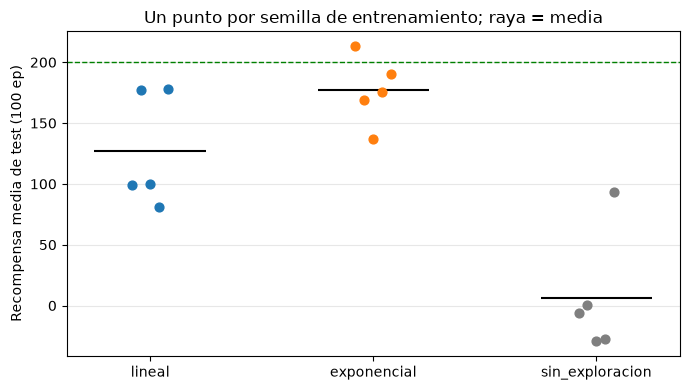

In [20]:
print(f"{'config':<16}" + ''.join(f"{'s' + str(s):>9}" for s in SEMILLAS_EXPERIMENTO)
      + f"{'media':>9}{'desv':>8}{'éxito':>8}{'min':>7}")
medias_por_config = {}
for nombre, corridas in resultados_exp.items():
    medias = np.array([c['test_recompensa_promedio'] for c in corridas])
    exitos = np.array([c['test_tasa_exito'] for c in corridas])
    tiempos = np.array([c['tiempo_s'] for c in corridas])
    medias_por_config[nombre] = medias
    print(f"{nombre:<16}" + ''.join(f"{m:9.1f}" for m in medias)
          + f"{medias.mean():9.1f}{medias.std(ddof=1):8.1f}{exitos.mean():8.1%}{tiempos.mean() / 60:7.1f}")

print("\nTasa de éxito en test por semilla:")
for nombre, corridas in resultados_exp.items():
    print(f"  {nombre:<16}", '  '.join(f"{c['test_tasa_exito']:5.0%}" for c in corridas))

print("\nComparación contra 'lineal' (recompensa media de test por semilla, n = 5 por grupo):")
referencia = medias_por_config['lineal']
for nombre in ['exponencial', 'sin_exploracion']:
    u = stats.mannwhitneyu(medias_por_config[nombre], referencia, alternative='two-sided')
    t = stats.ttest_ind(medias_por_config[nombre], referencia, equal_var=False)
    dif = medias_por_config[nombre].mean() - referencia.mean()
    print(f"  {nombre:<16} diferencia de medias = {dif:7.1f} | Mann-Whitney U = {u.statistic:4.1f}, "
          f"p = {u.pvalue:.4f} | Welch t = {t.statistic:6.2f}, p = {t.pvalue:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
for i, (nombre, medias) in enumerate(medias_por_config.items()):
    ax.scatter(np.full(len(medias), i) + np.linspace(-0.08, 0.08, len(medias)), medias,
               color=COLORES[nombre], s=40, zorder=3)
    ax.hlines(medias.mean(), i - 0.25, i + 0.25, color='black')
ax.set_xticks(range(len(medias_por_config)))
ax.set_xticklabels(list(medias_por_config))
ax.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1)
ax.set_ylabel('Recompensa media de test (100 ep)')
ax.set_title('Un punto por semilla de entrenamiento; raya = media')
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 11.6 Tiempos, configuración exacta y presupuesto para la ablación

Se guarda en `resultados/configuracion.json` todo lo necesario para reproducir los números de este
cuaderno, y se estima cuánto costaría la ablación del TODO 3 con este mismo presupuesto por corrida.

In [21]:
tiempos = {n: [c['tiempo_s'] for c in corridas] for n, corridas in resultados_exp.items()}
for nombre, ts in tiempos.items():
    pasos = np.mean([c['pasos_totales'] for c in resultados_exp[nombre]])
    print(f"{nombre:<16} {np.mean(ts) / 60:5.1f} ± {np.std(ts) / 60:4.1f} min por corrida "
          f"({EPISODIOS_EXPERIMENTO} ep, {pasos:,.0f} pasos de entorno en promedio)")
print(f"Entrenamiento principal (1200 ep): {tiempo_principal / 60:.1f} min")

minutos_corrida = np.mean(tiempos['lineal']) / 60
n_corridas_ablacion = 4 * 5                   # DQN completo + 3 variantes, 5 semillas
nucleos = os.cpu_count()
print(f"\nPresupuesto estimado para la ablación (4 configs × 5 semillas = {n_corridas_ablacion} corridas):")
print(f"  secuencial: {n_corridas_ablacion * minutos_corrida:.0f} min | "
      f"con {nucleos} núcleos: ≈ {np.ceil(n_corridas_ablacion / nucleos) * minutos_corrida:.0f} min")

configuracion = {
    'hiperparametros': {**HIPERPARAMETROS, 'capas_ocultas': list(HIPERPARAMETROS['capas_ocultas'])},
    'exploracion_principal': EXPLORACION_PRINCIPAL,
    'configuraciones_exploracion': CONFIGURACIONES,
    'semilla_principal': SEMILLA,
    'semillas_experimento': SEMILLAS_EXPERIMENTO,
    'semilla_entorno': '100000 + 1000*semilla + episodio',
    'semillas_validacion': [SEMILLA_VALIDACION, SEMILLA_VALIDACION + 9],
    'semillas_test': [SEMILLA_TEST, SEMILLA_TEST + EPISODIOS_TEST - 1],
    'episodios_principal': 1200,
    'episodios_experimento': EPISODIOS_EXPERIMENTO,
    'tiempo_principal_min': tiempo_principal / 60,
    'tiempo_medio_por_corrida_min': {n: float(np.mean(ts) / 60) for n, ts in tiempos.items()},
    'versiones': {'gymnasium': gym.__version__, 'torch': torch.__version__, 'numpy': np.__version__},
}
(CARPETA_RESULTADOS / 'configuracion.json').write_text(json.dumps(configuracion, indent=2))
print("\nGuardado en", CARPETA_RESULTADOS / 'configuracion.json')

lineal            11.6 ±  0.9 min por corrida (600 ep, 336,734 pasos de entorno en promedio)
exponencial        9.7 ±  0.9 min por corrida (600 ep, 302,853 pasos de entorno en promedio)
sin_exploracion   10.8 ±  1.1 min por corrida (600 ep, 388,374 pasos de entorno en promedio)
Entrenamiento principal (1200 ep): 10.1 min

Presupuesto estimado para la ablación (4 configs × 5 semillas = 20 corridas):
  secuencial: 231 min | con 8 núcleos: ≈ 35 min

Guardado en resultados\configuracion.json
